In [3]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import cross_val_score
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis 
from sklearn import datasets
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os

In [26]:
data = pd.read_csv(os.path.join(os.getcwd(), 'Datasets', 'sampled_merged_250_cleanforPCA.csv'))
data.head(20)

#define predictor and response variables
## X is all columns except last
X = data.iloc[:, :-1]
y = data['groupID']

#Fit the LDA model
model = LinearDiscriminantAnalysis()
model.fit(X, y)

,solver,'svd'
,shrinkage,None
,priors,None
,n_components,None
,store_covariance,False
,tol,0.0001
,covariance_estimator,None


In [28]:
#Define method to evaluate model
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=1)

#evaluate model
scores = cross_val_score(model, X, y, scoring='accuracy', cv=cv, n_jobs=-1)
print(np.mean(scores))   

0.7906264609630669


0.791 ± 0.034  (chance = 0.263)


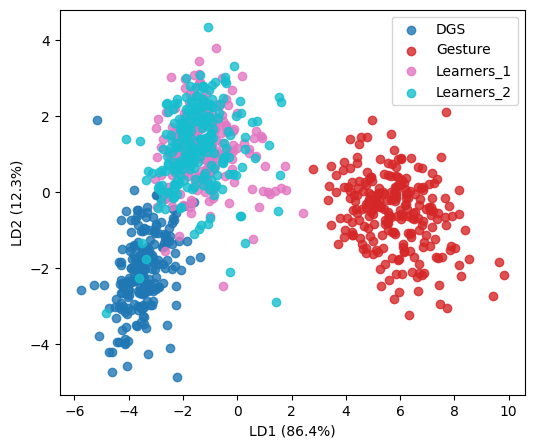

In [30]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

data = pd.read_csv(os.path.join(os.getcwd(), 'Datasets', 'sampled_merged_250_cleanforPCA.csv'))

y = data['groupID']
X = data.drop(columns=['groupID']).select_dtypes(include=[np.number])

pipe = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(n_components=2))

cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=1)
scores = cross_val_score(pipe, X, y, scoring='accuracy', cv=cv, n_jobs=-1)
print(f"{scores.mean():.3f} ± {scores.std():.3f}  (chance = {y.value_counts(normalize=True).max():.3f})")

pipe.fit(X, y)
data_plot = pipe.transform(X)
lda = pipe.named_steps['lineardiscriminantanalysis']

y_arr = y.to_numpy()
plt.figure(figsize=(6, 5))
colors = plt.cm.tab10(np.linspace(0, 1, len(lda.classes_)))

for color, cls in zip(colors, lda.classes_):
    m = y_arr == cls
    plt.scatter(data_plot[m, 0], data_plot[m, 1], alpha=.8, color=color, label=cls)
ev = lda.explained_variance_ratio_
plt.xlabel(f"LD1 ({ev[0]:.1%})")
plt.ylabel(f"LD2 ({ev[1]:.1%})")
plt.legend(loc='best', scatterpoints=1)
plt.show()

In [34]:
lda = pipe.named_steps['lineardiscriminantanalysis']
weights = pd.DataFrame(lda.scalings_[:, :2], index=X.columns, columns=['LD1', 'LD2'])
weights.reindex(weights.LD1.abs().sort_values(ascending=False).index).head(15)

,LD1,LD2
band1_0.5-2.0Hz_band_power_total_arm,-70.345277,278.609890
band2_2.0-5.0Hz_band_power_total_arm,-61.878378,244.971322
band3_5.0-8.0Hz_band_power_total_arm,-10.304798,40.799410
RIGHT_handshape_size_std,2.087520,-3.099880
RIGHT_handshape_size_mean,-2.086505,1.257500
RIGHT_mcp_tip_distance_std,1.218152,2.104441
intermittency_arm_total,0.672802,-0.380139
RIGHT_mcp_tip_distance_mean,-0.665038,-0.032991
head_horizontal_sd,0.627782,-0.280557
RIGHT_fingertip_speed_mean,0.448603,-0.473037


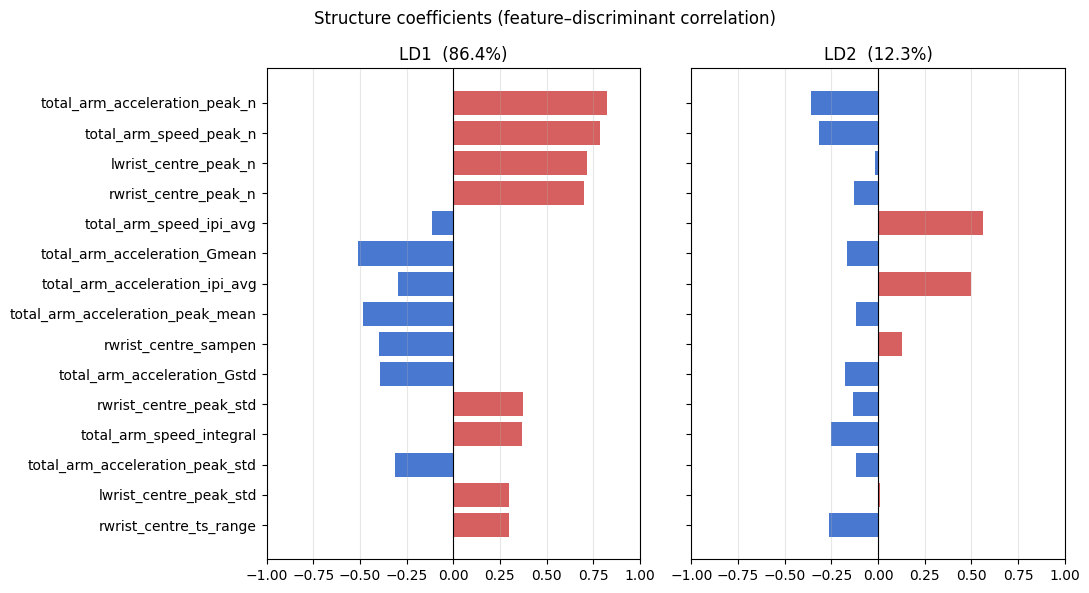

In [35]:
top = struct.reindex(struct.abs().max(axis=1).sort_values(ascending=False).index)[:15][::-1]

fig, axes = plt.subplots(1, 2, figsize=(11, 6), sharey=True)
for ax, ld in zip(axes, ['LD1', 'LD2']):
    v = top[ld]
    ax.barh(top.index, v, color=np.where(v < 0, '#4878d0', '#d65f5f'))
    ax.axvline(0, color='k', lw=.8)
    ax.set_xlim(-1, 1)
    ax.set_title(f"{ld}  ({ev[int(ld[-1])-1]:.1%})")
    ax.grid(axis='x', alpha=.3)
fig.suptitle('Structure coefficients (feature–discriminant correlation)')
plt.tight_layout()

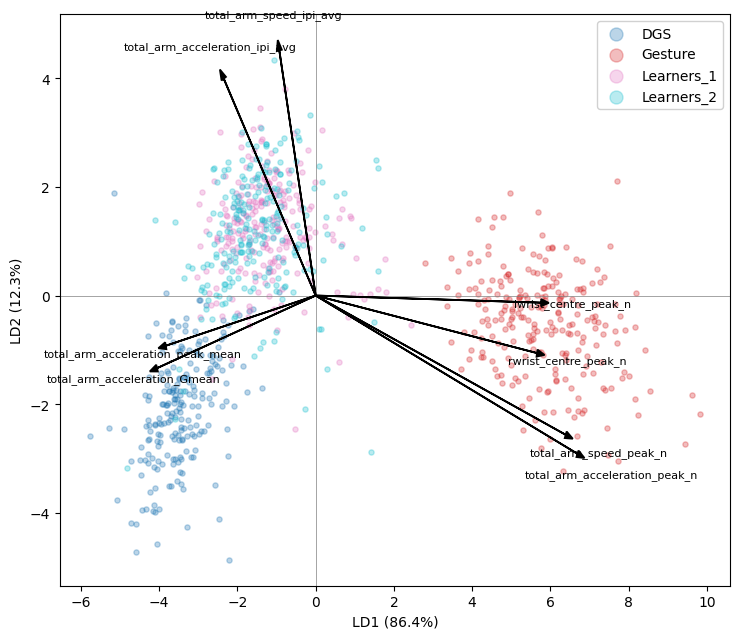

In [36]:
scores_lda = pipe.transform(X)[:, :2]
y_arr = y.to_numpy()
colors = plt.cm.tab10(np.linspace(0, 1, len(lda.classes_)))

fig, ax = plt.subplots(figsize=(7.5, 6.5))
for c, cls in zip(colors, lda.classes_):
    m = y_arr == cls
    ax.scatter(scores_lda[m, 0], scores_lda[m, 1], s=14, alpha=.30, color=c, label=cls)

k = 8
sel = struct[['LD1', 'LD2']].pow(2).sum(1).pow(.5).sort_values(ascending=False).index[:k]
scale = 0.85 * np.abs(scores_lda).max()
for f in sel:
    dx, dy = struct.loc[f, 'LD1'] * scale, struct.loc[f, 'LD2'] * scale
    ax.arrow(0, 0, dx, dy, color='k', lw=1.3, head_width=.13,
             length_includes_head=True, zorder=5)
    ax.text(dx * 1.10, dy * 1.10, f, fontsize=8, ha='center', va='center', zorder=6)

ax.axhline(0, color='grey', lw=.5); ax.axvline(0, color='grey', lw=.5)
ax.set_xlabel(f"LD1 ({ev[0]:.1%})"); ax.set_ylabel(f"LD2 ({ev[1]:.1%})")
ax.legend(markerscale=2.5, framealpha=.9)
plt.tight_layout()

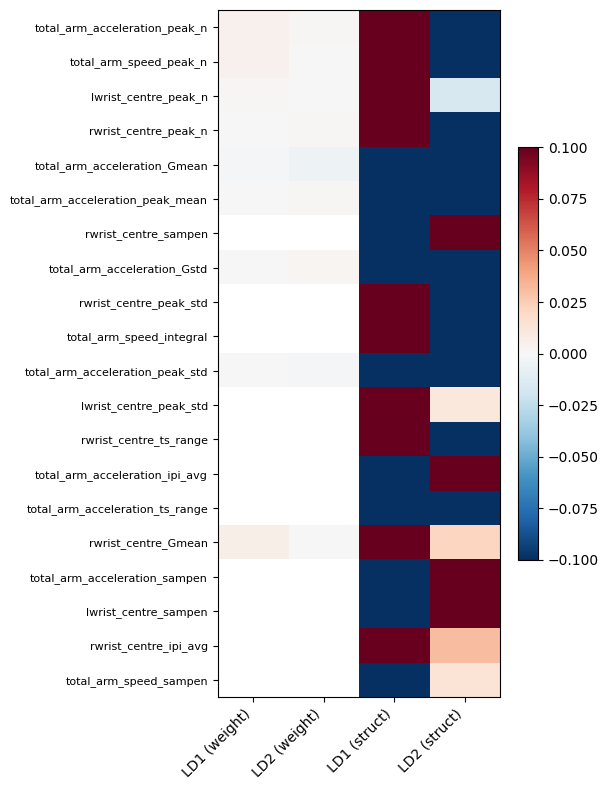

In [37]:
w = weights[['LD1', 'LD2']] / np.abs(weights[['LD1', 'LD2']]).max()   # rescale to compare
comp = pd.concat([w.add_suffix(' (weight)'), struct[['LD1', 'LD2']].add_suffix(' (struct)')], axis=1)
comp = comp.reindex(struct.LD1.abs().sort_values(ascending=False).index)[:20]

fig, ax = plt.subplots(figsize=(6, 8))
lim = np.abs(comp.values).max()
im = ax.imshow(comp.values, cmap='RdBu_r', vmin=-lim, vmax=lim, aspect='auto')
ax.set_xticks(range(comp.shape[1])); ax.set_xticklabels(comp.columns, rotation=45, ha='right')
ax.set_yticks(range(len(comp))); ax.set_yticklabels(comp.index, fontsize=8)
fig.colorbar(im, ax=ax, shrink=.6)
plt.tight_layout()

In [38]:
Xs = pipe.named_steps['standardscaler'].transform(X)
scores_lda = pipe.transform(X)[:, :2]

struct = pd.DataFrame(
    {f'LD{i+1}': [np.corrcoef(Xs[:, j], scores_lda[:, i])[0, 1] for j in range(Xs.shape[1])]
     for i in range(2)},
    index=X.columns)
struct.reindex(struct.LD1.abs().sort_values(ascending=False).index).head(15)

,LD1,LD2
RIGHT_mcp_tip_distance_std,0.875459,-0.126254
intermittency_arm_total,0.825084,-0.099679
RIGHT_mcp_tip_distance_mean,0.813735,-0.135407
head_horizontal_sd,0.720120,-0.117212
RIGHT_handshape_size_std,0.686090,-0.259889
total_arm_acceleration_peak_n,0.670595,-0.009506
total_arm_speed_peak_n,0.640113,-0.076214
RIGHT_fingertip_speed_mean,-0.529094,-0.292659
RIGHT_thumb_index_distance_mean,-0.481917,-0.042950
RIGHT_index_middle_distance_mean,-0.478789,-0.005853
